# <center>**College Starting Age and Academic Performance**

### Project Overview

Analyzed records of 4,424 undergraduate students, published on the UCI Machine Learning Repository, to examine whether age at enrollment relates to first-semester academic performance. The analysis separates two measures: whether students passed at least one first-semester unit, and the average grades earned by those who did.


### Research Questions

1. Does enrollment age have a meaningful relationship with first-semester grades?
2. Does the age difference appear in whether students pass their first-semester units, in the grades they earn, or both?

## **Data Preparation and Exploration**

In [1]:
# Import packages, ignore warnings, and print inline

import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
# Load in the dataset and show the first few rows

df = pd.read_csv('predict+students+dropout+and+academic+success.csv', sep=';')

display(df.head(5))

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
# Check dataset dimensions, columns, data types, missing values, and duplicates

print("Dataset shape:", df.shape)
df.info()

print("\nColumns:", df.columns.tolist())
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (4424, 37)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualif

In [4]:
# Summarize enrollment age, first-semester grades, and units passed

columns = [
    "Age at enrollment",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (approved)"]

display(df[columns].describe().round(2))

,Age at enrollment,Curricular units 1st sem (grade),Curricular units 1st sem (approved)
count,4424.00,4424.00,4424.00
mean,23.27,10.64,4.71
std,7.59,4.84,3.09
min,17.00,0.00,0.00
25%,19.00,11.00,3.00
50%,20.00,12.29,5.00
75%,25.00,13.40,6.00
max,70.00,18.88,26.00


In [5]:
# Confirm that a 0.0 first-semester grade means the student passed no first-semester units

zero_grade = df['Curricular units 1st sem (grade)'] == 0
no_units_passed = df['Curricular units 1st sem (approved)'] == 0

print("Students with a 0.0 grade:", zero_grade.sum())
print("Students who passed no units:", no_units_passed.sum())
print("Same students in both groups:", (zero_grade == no_units_passed).all())
print("Lowest grade above 0.0:", df.loc[~zero_grade, 'Curricular units 1st sem (grade)'].min())

Students with a 0.0 grade: 718
Students who passed no units: 718
Same students in both groups: True
Lowest grade above 0.0: 9.8


In [6]:
# Mark students who passed at least one first-semester unit and group students by enrollment age

df['Passed units'] = df['Curricular units 1st sem (approved)'] > 0
df['Age group'] = pd.cut(df['Age at enrollment'],
                         bins=[16, 19, 22, 25, 30, float("inf")],
                         labels=['17-19', '20-22', '23-25', '26-30', '31+'])

# Show the number of students, pass rate, and average grade of students who passed, by age group

passed = df[df['Passed units']]

age_summary = pd.DataFrame({
    'Students': df.groupby('Age group', observed=True).size(),
    'Pass rate (%)': df.groupby('Age group', observed=True)['Passed units'].mean().mul(100).round(1),
    'Average grade (passed)': passed.groupby('Age group', observed=True)['Curricular units 1st sem (grade)'].mean().round(2)
})

display(age_summary)
print("\nStudents in all groups:", age_summary['Students'].sum())

,Students,Pass rate (%),Average grade (passed)
Age group,,,
17-19,1952,88.2,12.90
20-22,1095,86.8,12.61
23-25,332,80.1,12.40
26-30,383,72.6,12.49
31+,662,74.2,12.48



Students in all groups: 4424


**Assessment**

* **Enrollment age:** 17–70 years with median 20 and average 23.27.
* **First-semester grades:** The average of 10.64 was well below the median (12.29). The 718 zero grades lowered the overall mean and were treated separately.
* **Units passed:** Average 4.71.
* **Students who passed:** 3,706 students passed at least one unit.
* **Lowest nonzero average grade:** 9.8 among students who passed at least one first-semester unit.

## **Data Visualization**

### VISUAL 1 - Histogram Showing Distribution of Enrollment Age

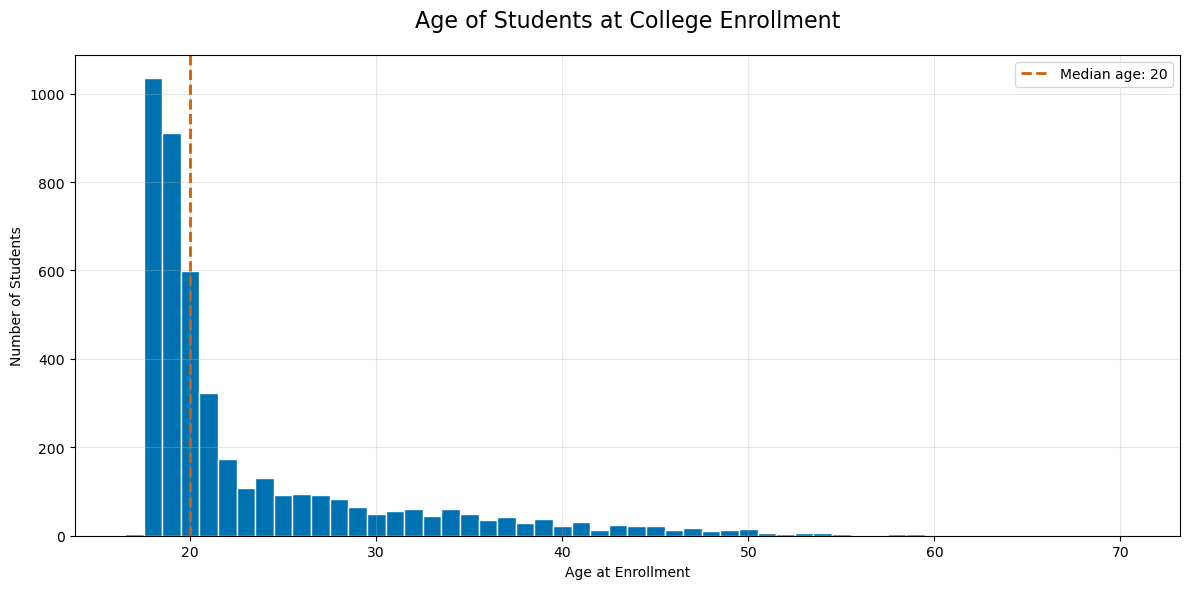

In [7]:
# Plot the distribution of enrollment age with one bar per year of age and mark the median

median_age = df['Age at enrollment'].median()

plt.figure(figsize=(12, 6))
plt.hist(df['Age at enrollment'], bins=[age - 0.5 for age in range(17, 72)], color='#0072B2', edgecolor='white')
plt.axvline(median_age, color='#D55E00', linestyle='--', linewidth=2, label=f'Median age: {median_age:.0f}')
plt.title('Age of Students at College Enrollment', fontsize=16, pad=20)
plt.xlabel('Age at Enrollment')
plt.ylabel('Number of Students')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Assessment**

The histogram shows that enrollment ages are heavily concentrated among younger students, particularly those aged 18 to 20. The median enrollment age is 20, meaning more than half of the students enrolled are age 20 or younger. The distribution is right-skewed, with progressively fewer students enrolling at older ages and a long tail extending to age 70. This imbalance is important when interpreting performance differences because the older age groups contain fewer students.

### VISUAL 2 - Scatter Plot Showing Enrollment Age Versus First-Semester Grades

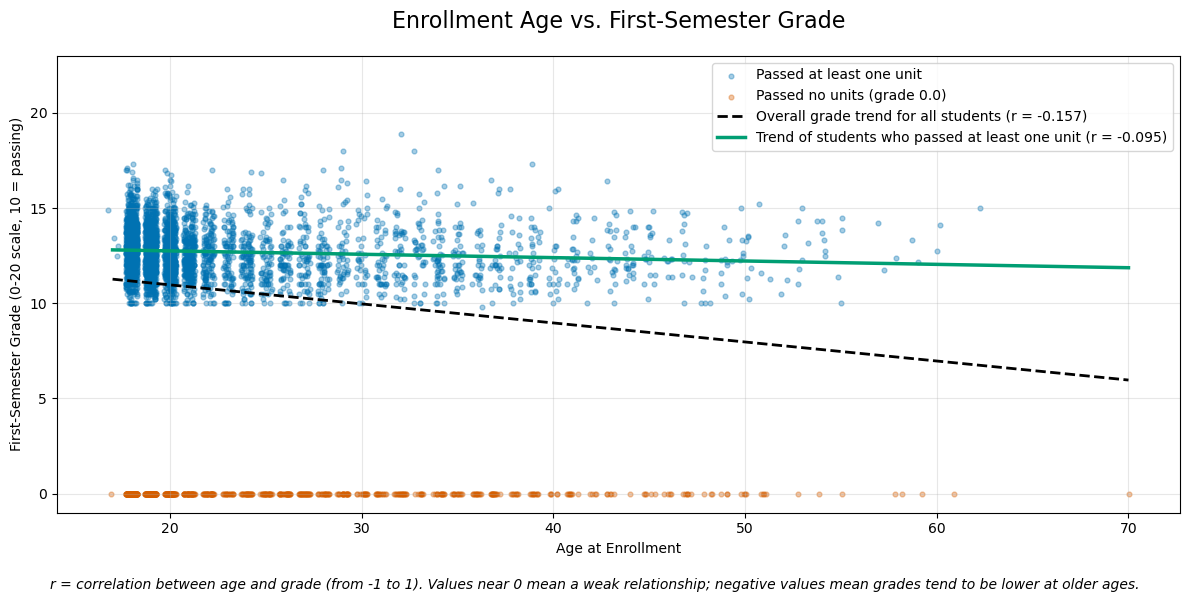

In [8]:
# Plot age against first-semester grade, with zero-grade students in a separate color and two trend lines

age = df['Age at enrollment']
grade = df['Curricular units 1st sem (grade)']
passed = df['Passed units']

# Spread points slightly left and right so students with the same age do not sit on top of each other
jitter = np.random.default_rng(42).uniform(-0.3, 0.3, len(df))

# Fit a straight trend line for all students and for students who passed at least one unit
slope_all, inter_all = np.polyfit(age, grade, 1)
slope_passed, inter_passed = np.polyfit(age[passed], grade[passed], 1)
r_all = age.corr(grade)
r_passed = age[passed].corr(grade[passed])
x_line = np.array([17, 70])

plt.figure(figsize=(12, 6))
plt.scatter(age[passed] + jitter[passed], grade[passed], s=12, alpha=0.35, color='#0072B2', label='Passed at least one unit')
plt.scatter(age[~passed] + jitter[~passed], grade[~passed], s=12, alpha=0.35, color='#D55E00', label='Passed no units (grade 0.0)')
plt.plot(x_line, inter_all + slope_all * x_line, color='black', linestyle='--', linewidth=2, label=f'Overall grade trend for all students (r = {r_all:.3f})')
plt.plot(x_line, inter_passed + slope_passed * x_line, color='#009E73', linewidth=2.5, label=f'Trend of students who passed at least one unit (r = {r_passed:.3f})')
plt.title('Enrollment Age vs. First-Semester Grade', fontsize=16, pad=20)
plt.xlabel('Age at Enrollment')
plt.ylabel('First-Semester Grade (0-20 scale, 10 = passing)')
plt.ylim(-1, 23)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.figtext(0.5, 0.01, 'r = correlation between age and grade (from -1 to 1). Values near 0 mean a weak relationship; negative values mean grades tend to be lower at older ages.', ha='center', fontsize=10, style='italic')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Assessment**

The scatter plot shows a weak negative relationship between enrollment age and first-semester grades for all 4,424 students (r = −0.157). However, this relationship becomes even weaker (r = −0.095) when the 718 students who passed no first-semester units are excluded. The nearly flat trend line among students who passed at least one unit suggests that their grades vary relatively little with enrollment age. This indicates that much of the overall difference is associated with students who passed no units, rather than substantially lower grades among older students who passed units.

### VISUAL 3 - Waffle Chart Showing First-Semester Pass Rates by Enrollment Age

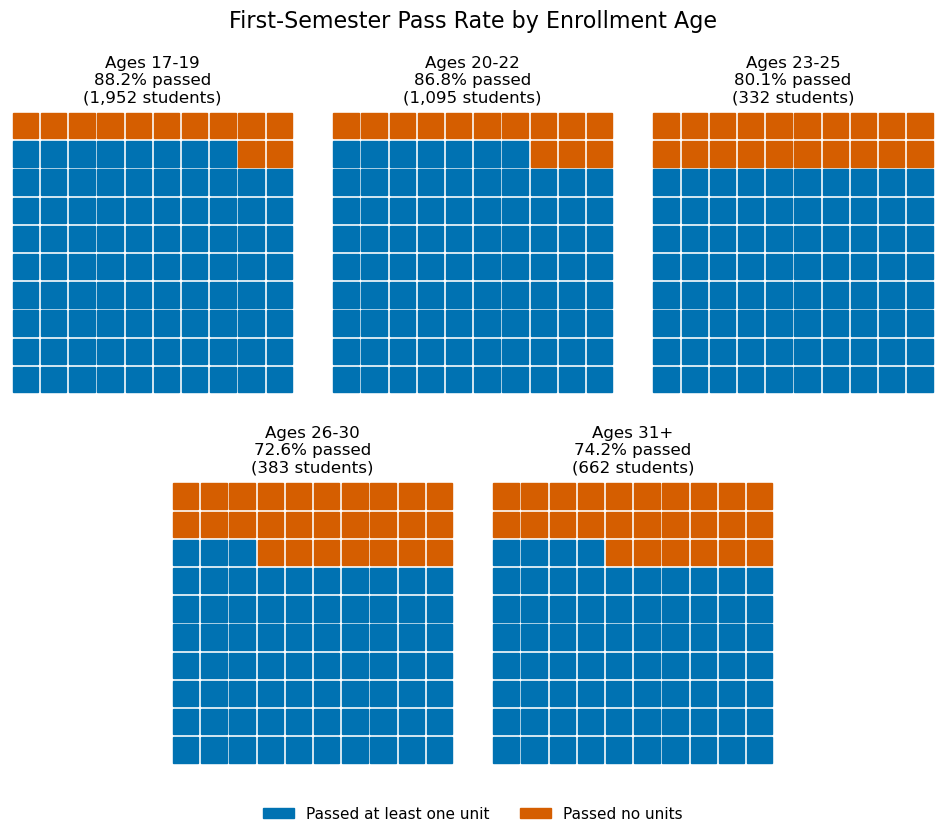

In [9]:
# Show the pass rate of each age group as a grid of 100 squares (one square = 1% of students)

pass_rate = df.groupby('Age group', observed=True)['Passed units'].mean().mul(100)
group_size = df.groupby('Age group', observed=True).size()

# Arrange the five grids in two rows: three on top and two centered below
fig = plt.figure(figsize=(10, 8.4))
grid = fig.add_gridspec(2, 6, left=0.03, right=0.97, top=0.86, bottom=0.08, hspace=0.3, wspace=0.15)
axes = [fig.add_subplot(grid[0, 0:2]), fig.add_subplot(grid[0, 2:4]), fig.add_subplot(grid[0, 4:6]),
        fig.add_subplot(grid[1, 1:3]), fig.add_subplot(grid[1, 3:5])]

for ax, (group, rate) in zip(axes, pass_rate.items()):
    shaded = round(rate)
    for i in range(100):
        row, col = divmod(i, 10)
        color = '#0072B2' if i < shaded else '#D55E00'
        ax.add_patch(plt.Rectangle((col, row), 0.9, 0.9, color=color))
    ax.set_xlim(-0.1, 10)
    ax.set_ylim(-0.1, 10)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f'Ages {group}\n{rate:.1f}% passed\n({group_size[group]:,} students)', fontsize=12)

fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#0072B2'), plt.Rectangle((0, 0), 1, 1, color='#D55E00')],
           labels=['Passed at least one unit', 'Passed no units'], loc='lower center', ncol=2, frameon=False, fontsize=11)
fig.suptitle('First-Semester Pass Rate by Enrollment Age', fontsize=16, y=0.98)
plt.show()

**Assessment**

The waffle chart shows that first-semester pass rates generally decline as enrollment age increases. Students aged 17–19 had the highest pass rate at 88.2%, compared with 72.6% for ages 26–30 and 74.2% for ages 31 and older. This represents a difference of approximately 14 to 16 percentage points. The slight rise for students aged 31 and older is based on a larger group (662 students) than ages 23–25 (332) or 26–30 (383). Although most students in every age group passed at least one unit, older students were more likely to pass none. These results reinforce the earlier finding that enrollment age is more strongly associated with whether students pass first-semester units than with the grades earned by those who do.

### VISUAL 4 - Box Plots Showing First-Semester Grades of Students Who Passed by Enrollment Age

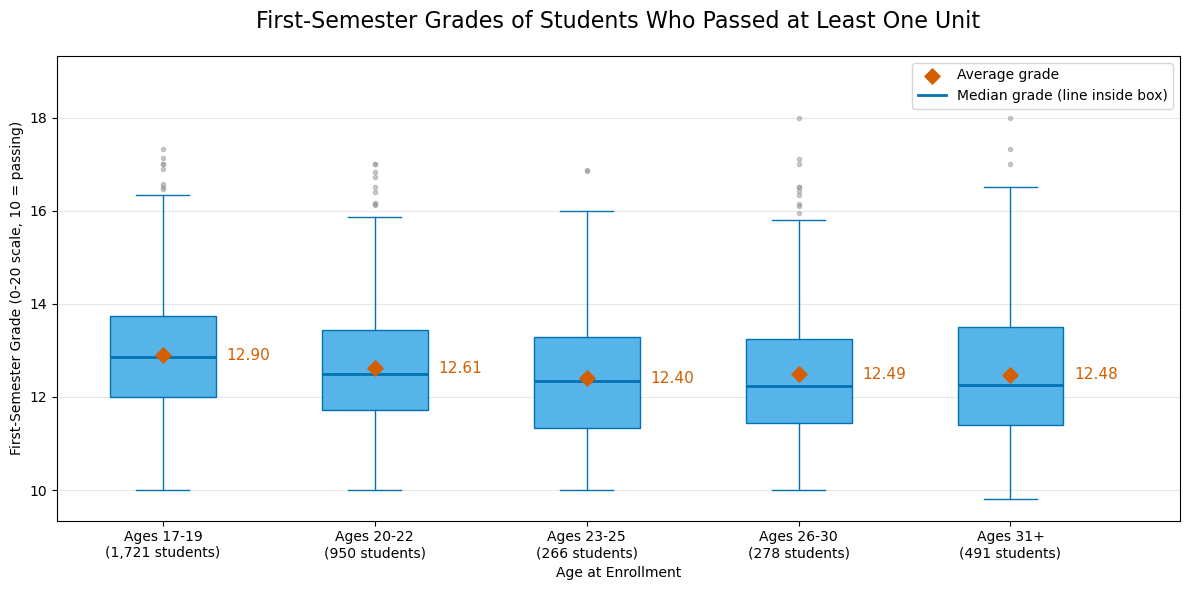

In [10]:
# Compare first-semester grades across age groups, using only students who passed at least one unit

passed = df[df['Passed units']]
groups = passed['Age group'].cat.categories
grades_by_group = [passed.loc[passed['Age group'] == g, 'Curricular units 1st sem (grade)'] for g in groups]
averages = [grades.mean() for grades in grades_by_group]

plt.figure(figsize=(12, 6))
plt.boxplot(grades_by_group, widths=0.5, patch_artist=True,
            boxprops=dict(facecolor='#56B4E9', color='#0072B2'),
            medianprops=dict(color='#0072B2', linewidth=2),
            whiskerprops=dict(color='#0072B2'), capprops=dict(color='#0072B2'),
            flierprops=dict(marker='o', markersize=3, markerfacecolor='#999999', markeredgecolor='#999999', alpha=0.5))
plt.scatter(range(1, len(groups) + 1), averages, marker='D', s=60, color='#D55E00', zorder=3, label='Average grade')

# Label each average beside its box
for x, avg in enumerate(averages, start=1):
    plt.text(x + 0.3, avg, f'{avg:.2f}', va='center', fontsize=11, color='#D55E00')

plt.xticks(range(1, len(groups) + 1), [f'Ages {g}\n({len(gr):,} students)' for g, gr in zip(groups, grades_by_group)])
plt.title('First-Semester Grades of Students Who Passed at Least One Unit', fontsize=16, pad=20)
plt.xlabel('Age at Enrollment')
plt.ylabel('First-Semester Grade (0-20 scale, 10 = passing)')
plt.plot([], [], color='#0072B2', linewidth=2, label='Median grade (line inside box)')
plt.xlim(0.5, len(groups) + 0.8)
plt.legend(loc='upper right')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Assessment**

The box plots show that first-semester grades among students who passed at least one unit were relatively similar across enrollment age groups, although a small decline is noticeable. Average grades fell from 12.90 for ages 17–19 to 12.40 for ages 23–25, then increased slightly and remained nearly unchanged among older students. The distributions also show considerable overlap, with greater variation within age groups than between their averages. While the gradual decline among younger age groups is noteworthy, the overall difference of just half a point suggests that enrollment age has a much weaker relationship with grades among students who passed units than with whether students passed any units.

### VISUAL 5 - Combined Summary Dot Plot of Pass Rates and Average Grades by Enrollment Age

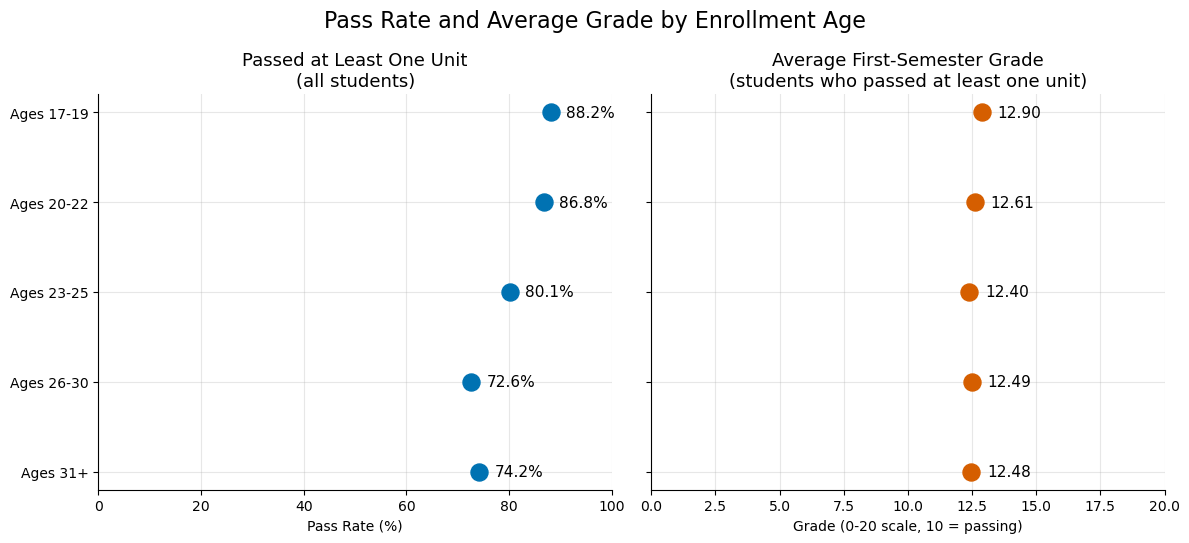

In [11]:
# Show both measures side by side for each age group: pass rate (all students) and average grade (students who passed)

pass_rate = df.groupby('Age group', observed=True)['Passed units'].mean().mul(100)
avg_grade = df[df['Passed units']].groupby('Age group', observed=True)['Curricular units 1st sem (grade)'].mean()
labels = [f'Ages {g}' for g in pass_rate.index]
y = range(len(labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)

# Left panel: pass rate on its full 0-100% scale
ax1.scatter(pass_rate, y, s=150, color='#0072B2', zorder=3)
for i, rate in enumerate(pass_rate):
    ax1.text(rate + 3, i, f'{rate:.1f}%', va='center', ha='left', fontsize=11)
ax1.set_xlim(0, 100)
ax1.set_title('Passed at Least One Unit\n(all students)', fontsize=13)
ax1.set_xlabel('Pass Rate (%)')

# Right panel: average grade on its full 0-20 scale
ax2.scatter(avg_grade, y, s=150, color='#D55E00', zorder=3)
for i, grade in enumerate(avg_grade):
    ax2.text(grade + 0.6, i, f'{grade:.2f}', va='center', ha='left', fontsize=11)
ax2.set_xlim(0, 20)
ax2.set_title('Average First-Semester Grade\n(students who passed at least one unit)', fontsize=13)
ax2.set_xlabel('Grade (0-20 scale, 10 = passing)')

ax1.set_yticks(list(y), labels)
ax1.invert_yaxis()
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Pass Rate and Average Grade by Enrollment Age', fontsize=16)
plt.tight_layout()
plt.show()

**Assessment**

The combined dot plot brings together the two measures of first-semester performance and highlights their different relationships with enrollment age. Pass rates generally declined from 88.2% among students aged 17–19 to 74.2% among those aged 31 and older, with the lowest rate of 72.6% occurring among ages 26–30. In contrast, average grades among students who passed at least one unit showed a much smaller change. Grades declined from 12.90 for ages 17–19 to 12.40 for ages 23–25, then remained nearly unchanged at approximately 12.5 among older students. While both measures showed some decline with enrollment age, the differences were considerably greater in pass rates than in average grades. These findings suggest that enrollment age is more strongly associated with whether students pass first-semester units than with the grades earned by those who do.

## **Conclusion**

Enrollment age showed a weak negative relationship with first-semester grades. Most of this difference came from students who passed no first-semester units, which occurred more than twice as often among students aged 26 and older as among those aged 17–19. Among students who passed units, grades were nearly identical across age groups. These findings suggest that enrollment age is more strongly associated with whether students pass their first-semester units than with the grades earned by those who do.